# Resting-state Functional Magnetic Resonance Imaging (fMRI) Brain Network Estimation

This is starter code for estimating the functional brain network from 30 resting-state fMRI. This is adapted from the Nilearn example code found here:

[https://nilearn.github.io/dev/auto_examples/03_connectivity/plot_group_level_connectivity.html](https://nilearn.github.io/dev/auto_examples/03_connectivity/plot_group_level_connectivity.html)

We deviate from the example in that we are going to compute the covariance matrix from the fMRI data, then optimize a sparse Gaussian graphical model estimation (a.k.a., the precision matrix) from that.

## Load brain development `fMRI` dataset and MSDL atlas
We study only 30 subjects from the dataset, to save computation time.

In [1]:
from nilearn.datasets import fetch_atlas_msdl, fetch_development_fmri
from nilearn.plotting import plot_connectome, plot_matrix, show

development_dataset = fetch_development_fmri(n_subjects=30)

[fetch_development_fmri] Dataset directory found: /home/ptf8v/nilearn_data/development_fmri


We use probabilistic regions of interest (ROIs) from the MSDL atlas.



In [2]:
msdl_data = fetch_atlas_msdl()
msdl_coords = msdl_data.region_coords
n_regions = len(msdl_coords)
print(
    f"MSDL has {n_regions} ROIs, "
    f"part of the following networks:\n{msdl_data.networks}."
)

[fetch_atlas_msdl] Dataset directory found: /home/ptf8v/nilearn_data/msdl_atlas
MSDL has 39 ROIs, part of the following networks:
['Aud', 'Aud', 'Striate', 'DMN', 'DMN', 'DMN', 'DMN', 'Occ post', 'Motor', 'R V Att', 'R V Att', 'R V Att', 'R V Att', 'Basal', 'L V Att', 'L V Att', 'L V Att', 'D Att', 'D Att', 'Vis Sec', 'Vis Sec', 'Vis Sec', 'Salience', 'Salience', 'Salience', 'Temporal', 'Temporal', 'Language', 'Language', 'Language', 'Language', 'Language', 'Cereb', 'Dors PCC', 'Cing-Ins', 'Cing-Ins', 'Cing-Ins', 'Ant IPS', 'Ant IPS'].


## Region signals extraction
To extract regions time series, we instantiate a
:class:`~nilearn.maskers.NiftiMapsMasker` object and pass the atlas the
file name to it, as well as filtering band-width and detrending option.



In [3]:
from nilearn.maskers import NiftiMapsMasker

masker = NiftiMapsMasker(
    msdl_data.maps,
    resampling_target="data",
    t_r=development_dataset.t_r,
    detrend=True,
    low_pass=0.1,
    high_pass=0.01,
    standardize="zscore_sample",
    memory="nilearn_cache",
    memory_level=1,
    standardize_confounds=True,
    verbose=1,
)

Then we compute region signals and extract useful phenotypic information.



In [10]:
children = []
pooled_subjects = []
groups = []  # child or adult
for func_file, confound_file, phenotype in zip(
    development_dataset.func,
    development_dataset.confounds,
    development_dataset.phenotypic["Child_Adult"],
    strict=False,
):
    time_series = masker.fit_transform(func_file, confounds=confound_file)
    pooled_subjects.append(time_series)
    if phenotype == "child":
        children.append(time_series)
    groups.append(phenotype)

print(f"Data has {len(children)} children.")

[NiftiMapsMasker.wrapped] Loading data from sub-pixar128_task-...
[NiftiMapsMasker.wrapped] Loading regions from .../msdl_rois.nii
[NiftiMapsMasker.wrapped] Resampling regions
[NiftiMapsMasker.wrapped] Finished fit
[NiftiMapsMasker.wrapped] Loading data from sub-pixar126_task-...
[NiftiMapsMasker.wrapped] Loading regions from .../msdl_rois.nii
[NiftiMapsMasker.wrapped] Resampling regions
[NiftiMapsMasker.wrapped] Finished fit
[NiftiMapsMasker.wrapped] Loading data from sub-pixar125_task-...
[NiftiMapsMasker.wrapped] Loading regions from .../msdl_rois.nii
[NiftiMapsMasker.wrapped] Resampling regions
[NiftiMapsMasker.wrapped] Finished fit
[NiftiMapsMasker.wrapped] Loading data from sub-pixar124_task-...
[NiftiMapsMasker.wrapped] Loading regions from .../msdl_rois.nii
[NiftiMapsMasker.wrapped] Resampling regions
[NiftiMapsMasker.wrapped] Finished fit
[NiftiMapsMasker.wrapped] Loading data from sub-pixar123_task-...
[NiftiMapsMasker.wrapped] Loading regions from .../msdl_rois.nii
[NiftiMap

## ROI-to-ROI covariances of children
This is the covariance between fMRI time series in pairs of regions-of-interest (ROI). First, we estimate a covariance matrix for each person, then we aggregate them all in to a single mean covariance matrix.



In [11]:
from nilearn.connectome import ConnectivityMeasure

covariance_measure = ConnectivityMeasure(kind="covariance", verbose=1)

In [12]:
covariance_matrices = covariance_measure.fit_transform(children)

# All individual coefficients are stacked in a unique 2D matrix.
print(
    "Covariances of children are stacked "
    f"in an array of shape {covariance_matrices.shape}"
)

[ConnectivityMeasure.wrapped] Finished fit
Covariances of children are stacked in an array of shape (24, 39, 39)


In [20]:
mean_covariance_matrix = covariance_measure.mean_
print(f"Mean covariance has shape {mean_covariance_matrix.shape}.")

Mean covariance has shape (39, 39).


# Plot Examples

Next we show how to plot a covariance matrix, both as a matrix and as a graph with vertices as regions in the brain and edges as covariance between two regions' time series.


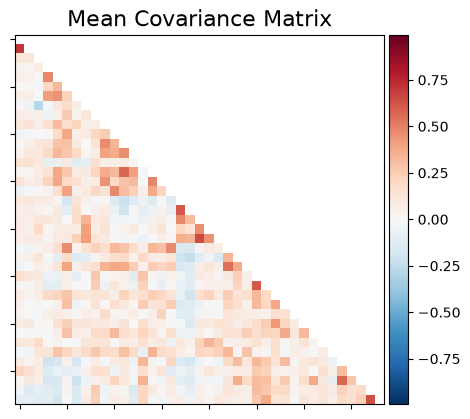

In [21]:
import numpy as np
from matplotlib import pyplot as plt

_, ax = plt.subplots()
vmax = np.absolute(mean_covariance_matrix).max()
plot_matrix(mean_covariance_matrix, tri="lower", axes=ax, title=f"Mean Covariance Matrix", vmax=vmax, vmin=-vmax);

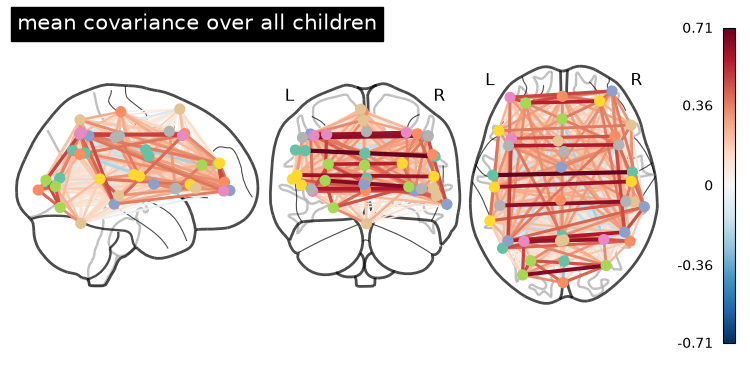

In [25]:
plot_connectome(
    mean_covariance_matrix,
    msdl_coords,
    title="mean covariance over all children",
);